In [1]:
# ============================================================
# PROJET 6 — PRÉDICTION DE PRIX IMMOBILIERS
# ============================================================
# Dataset  : Ames Housing (Iowa, USA) — ~1 460 maisons, 80 variables
# Objectif : prédire le prix de vente d'une maison
# Concepts : régression, feature engineering, Ridge/Lasso,
#            cross-validation, RMSE
# ============================================================

import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.datasets import fetch_openml

# --- Chargement du dataset ---
maisons = fetch_openml(name="house_prices", as_frame=True, parser="auto")
df = maisons.frame

print(f" *Dimensions : {df.shape[0]:,} maisons × {df.shape[1]} colonnes")
print(f"\n *Variable à prédire : SalePrice")
df[["SalePrice", "GrLivArea", "OverallQual", "YearBuilt", "Neighborhood"]].head()

 *Dimensions : 1,460 maisons × 81 colonnes

 *Variable à prédire : SalePrice


,SalePrice,GrLivArea,OverallQual,YearBuilt,Neighborhood
0,208500,1710,7,2003,CollgCr
1,181500,1262,6,1976,Veenker
2,223500,1786,7,2001,CollgCr
3,140000,1717,7,1915,Crawfor
4,250000,2198,8,2000,NoRidge


 Types de variables :
object     43
int64      35
float64     3
Name: count, dtype: int64

'Id' présent dans les colonnes : True

 19 colonnes avec des valeurs manquantes :

              Manquants  Pourcentage
PoolQC             1453         99.5
MiscFeature        1406         96.3
Alley              1369         93.8
Fence              1179         80.8
FireplaceQu         690         47.3
LotFrontage         259         17.7
GarageType           81          5.5
GarageYrBlt          81          5.5
GarageFinish         81          5.5
GarageQual           81          5.5
GarageCond           81          5.5
BsmtExposure         38          2.6
BsmtFinType2         38          2.6
BsmtFinType1         37          2.5
BsmtCond             37          2.5
BsmtQual             37          2.5
MasVnrArea            8          0.5
MasVnrType            8          0.5
Electrical            1          0.1

 Statistiques du prix de vente :
count      1460.0
mean     180921.0
std       79443.

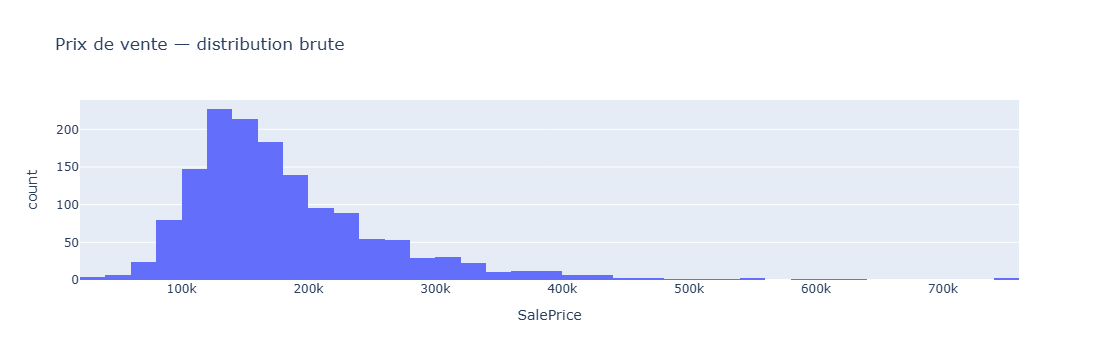

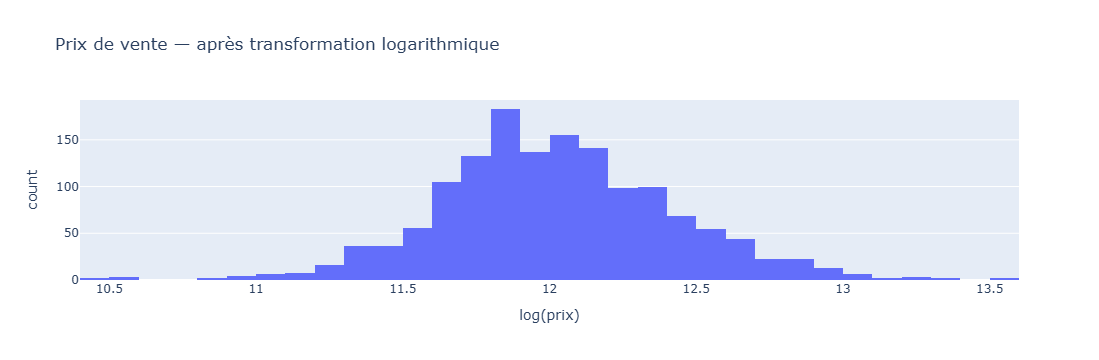

In [2]:
# ============================================================
# DIAGNOSTIC + DISTRIBUTION DE LA CIBLE
# ============================================================

# --- 1. Types de variables ---
print(" Types de variables :")
print(df.dtypes.value_counts())
print("\n'Id' présent dans les colonnes :", "Id" in df.columns)

# --- 2. Valeurs manquantes ---
manquants = pd.DataFrame({
    "Manquants": df.isnull().sum(),
    "Pourcentage": (df.isnull().sum() / len(df) * 100).round(1)
})
manquants = manquants[manquants["Manquants"] > 0].sort_values("Manquants", ascending=False)
print(f"\n {len(manquants)} colonnes avec des valeurs manquantes :\n")
print(manquants)

# --- 3. Distribution du prix de vente ---
print("\n Statistiques du prix de vente :")
print(df["SalePrice"].describe().round(0))
print(f"\nMoyenne : {df['SalePrice'].mean():,.0f} $ | Médiane : {df['SalePrice'].median():,.0f} $")
print(f"Asymétrie avant log : {df['SalePrice'].skew():.2f}")
print(f"Asymétrie après log : {np.log1p(df['SalePrice']).skew():.2f}")

# --- 4. Visualisation avant / après transformation ---
fig1 = px.histogram(df, x="SalePrice", nbins=50,
                    title="Prix de vente — distribution brute")
fig1.show()

fig2 = px.histogram(x=np.log1p(df["SalePrice"]), nbins=50,
                    title="Prix de vente — après transformation logarithmique",
                    labels={"x": "log(prix)"})
fig2.show()

In [3]:
# ============================================================
# TRAITEMENT DES ABSENCES + SÉPARATION TRAIN/TEST
# ============================================================

from sklearn.model_selection import train_test_split

# --- 1. Règle métier : NaN = "l'équipement n'existe pas" (pas de fuite possible) ---
absences_texte = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
                  "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                  "BsmtExposure", "BsmtFinType2", "BsmtFinType1",
                  "BsmtCond", "BsmtQual", "MasVnrType"]
df[absences_texte] = df[absences_texte].fillna("None")
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

# Une maison sans garage n'a pas d'année de construction de garage :
# on garde l'information dans un indicateur, puis on remplace par l'année de la maison
df["HasGarage"] = (df["GarageType"] != "None").astype(int)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])

# --- 2. Séparer la cible (y) des variables (X) ---
y = np.log1p(df["SalePrice"])                       # on prédit le log du prix
X = df.drop(columns=["SalePrice", "Id"], errors="ignore")

# --- 3. Séparation train / test (80 % / 20 %) ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f" Train : {X_train.shape[0]} maisons")
print(f" Test  : {X_test.shape[0]} maisons")
print(f"\n Manquants restants dans le train :")
restants = X_train.isnull().sum()
print(restants[restants > 0])

 Train : 1168 maisons
 Test  : 292 maisons

 Manquants restants dans le train :
LotFrontage    217
Electrical       1
dtype: int64


In [4]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

# Échelle ordinale des notes de qualité : un ordre, pas des catégories indépendantes
echelle_qualite = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
colonnes_qualite = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                    "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]

def ajouter_features(data):
    """Crée de nouvelles variables. Opérations ligne par ligne : aucune fuite possible."""
    data = data.copy()

    # --- Surfaces et confort ---
    data["TotalSF"] = data["TotalBsmtSF"] + data["1stFlrSF"] + data["2ndFlrSF"]
    data["TotalBath"] = (data["FullBath"] + 0.5 * data["HalfBath"]
                         + data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"])
    data["TotalPorchSF"] = (data["OpenPorchSF"] + data["EnclosedPorch"]
                            + data["3SsnPorch"] + data["ScreenPorch"] + data["WoodDeckSF"])

    # --- Âges ---
    data["HouseAge"] = data["YrSold"] - data["YearBuilt"]
    data["RemodAge"] = data["YrSold"] - data["YearRemodAdd"]

    # --- Indicateurs 0/1 ---
    data["HasPool"] = (data["PoolArea"] > 0).astype(int)
    data["HasFireplace"] = (data["Fireplaces"] > 0).astype(int)
    data["Has2ndFloor"] = (data["2ndFlrSF"] > 0).astype(int)
    data["IsRemodeled"] = (data["YearBuilt"] != data["YearRemodAdd"]).astype(int)

    # --- Notes de qualité : texte -> nombre ordonné ---
    for colonne in colonnes_qualite:
        data[colonne] = data[colonne].map(echelle_qualite)

    # --- MSSubClass : un code, pas une quantité ---
    data["MSSubClass"] = data["MSSubClass"].astype(str)

    return data

# On applique EXACTEMENT la même fonction au train et au test
X_train = ajouter_features(X_train)
X_test = ajouter_features(X_test)

print(f" Variables après feature engineering : {X_train.shape[1]}")

# --- Les nouvelles variables sont-elles utiles ? Corrélation avec le log du prix ---
nouvelles = ["TotalSF", "TotalBath", "TotalPorchSF", "HouseAge", "RemodAge",
             "HasPool", "HasFireplace", "Has2ndFloor", "IsRemodeled"]
correlations = X_train[nouvelles].corrwith(y_train).round(3).sort_values(ascending=False)
print("\n Corrélation des nouvelles variables avec le log du prix :\n")
print(correlations)

print("\n Pour comparaison — variables d'origine :")
print(X_train[["GrLivArea", "OverallQual", "YearBuilt"]].corrwith(y_train).round(3))

 Variables après feature engineering : 89

 Corrélation des nouvelles variables avec le log du prix :

TotalSF         0.762
TotalBath       0.659
HasFireplace    0.507
TotalPorchSF    0.396
Has2ndFloor     0.140
HasPool         0.084
IsRemodeled    -0.074
RemodAge       -0.564
HouseAge       -0.577
dtype: float64

 Pour comparaison — variables d'origine :
GrLivArea      0.689
OverallQual    0.808
YearBuilt      0.577
dtype: float64


In [5]:
# ============================================================
# PRÉPROCESSING + BASELINE + RÉGRESSION LINÉAIRE
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

# --- 1. Séparer les colonnes numériques et catégorielles ---
colonnes_cat = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
colonnes_num = [c for c in X_train.columns if c not in colonnes_cat]
X_train[colonnes_cat] = X_train[colonnes_cat].astype(object)
X_test[colonnes_cat] = X_test[colonnes_cat].astype(object)
print(f" {len(colonnes_num)} variables numériques |  {len(colonnes_cat)} variables catégorielles")

# --- 2. Préprocesseur : une chaîne pour chaque type de variable ---
transformeur_num = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler()),
])
transformeur_cat = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore")),
])
preprocesseur = ColumnTransformer([
    ("num", transformeur_num, colonnes_num),
    ("cat", transformeur_cat, colonnes_cat),
])

# --- 3. Fonction pour mesurer un modèle ---
def evaluer(modele, nom):
    modele.fit(X_train, y_train)
    rmse_train = np.sqrt(mean_squared_error(y_train, modele.predict(X_train)))
    rmse_test = np.sqrt(mean_squared_error(y_test, modele.predict(X_test)))
    print(f"{nom:<24} | RMSE train : {rmse_train:.4f} | RMSE test : {rmse_test:.4f}")
    return rmse_train, rmse_test

# --- 4. Baseline : prédire toujours la moyenne ---
baseline = Pipeline([("prep", preprocesseur), ("modele", DummyRegressor(strategy="mean"))])
evaluer(baseline, "Baseline (moyenne)")

# --- 5. Régression linéaire ---
lineaire = Pipeline([("prep", preprocesseur), ("modele", LinearRegression())])
evaluer(lineaire, "Régression linéaire")

 55 variables numériques |  34 variables catégorielles
Baseline (moyenne)       | RMSE train : 0.3904 | RMSE test : 0.4332
Régression linéaire      | RMSE train : 0.0925 | RMSE test : 0.1270


(np.float64(0.09248773310909368), np.float64(0.1270063512395919))

In [6]:
# ============================================================
# CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_rmse(modele, nom):
    """RMSE sur 5 plis, calculé uniquement sur le jeu d'entraînement."""
    scores = -cross_val_score(modele, X_train, y_train, cv=kf,
                              scoring="neg_root_mean_squared_error")
    print(f"{nom:<22} | RMSE moyen : {scores.mean():.4f} "
          f"| écart-type : {scores.std():.4f} "
          f"| par pli : {np.round(scores, 3)}")
    return scores

# Nombre de colonnes réellement vues par le modèle après encodage
nb_colonnes = lineaire.named_steps["prep"].transform(X_train).shape[1]
print(f" {X_train.shape[0]} maisons pour {nb_colonnes} colonnes après encodage\n")

scores_base = cv_rmse(baseline, "Baseline (moyenne)")
scores_lin = cv_rmse(lineaire, "Régression linéaire")

 1168 maisons pour 284 colonnes après encodage

Baseline (moyenne)     | RMSE moyen : 0.3901 | écart-type : 0.0182 | par pli : [0.406 0.396 0.411 0.372 0.365]
Régression linéaire    | RMSE moyen : 0.1636 | écart-type : 0.0266 | par pli : [0.14  0.164 0.213 0.141 0.16 ]


In [7]:
# ============================================================
# RIDGE ET LASSO (alpha choisi par cross-validation)
# ============================================================

from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV

def chercher_alpha(modele, grille_alpha, nom):
    """Teste plusieurs valeurs d'alpha en cross-validation (sur le train uniquement)."""
    pipe = Pipeline([("prep", preprocesseur), ("modele", modele)])
    recherche = GridSearchCV(pipe, {"modele__alpha": grille_alpha},
                             cv=kf, scoring="neg_root_mean_squared_error")
    recherche.fit(X_train, y_train)

    resultats = pd.DataFrame({
        "alpha": grille_alpha,
        "RMSE_CV": -recherche.cv_results_["mean_test_score"],
        "ecart_type": recherche.cv_results_["std_test_score"],
    }).round(4)
    print(f"\n {nom} — RMSE en cross-validation selon alpha :\n")
    print(resultats.to_string(index=False))
    print(f"\n Meilleur alpha : {recherche.best_params_['modele__alpha']} "
          f"| RMSE CV : {-recherche.best_score_:.4f}")
    return recherche

# --- Ridge ---
rech_ridge = chercher_alpha(Ridge(),
                            [0.1, 1, 3, 10, 30, 100, 300], "Ridge")

# --- Lasso (max_iter élevé pour garantir la convergence) ---
rech_lasso = chercher_alpha(Lasso(max_iter=20000),
                            [0.0003, 0.001, 0.003, 0.01, 0.03], "Lasso")

# --- Lasso : quelles variables a-t-il gardées ? ---
meilleur_lasso = rech_lasso.best_estimator_
coefs = meilleur_lasso.named_steps["modele"].coef_
noms = meilleur_lasso.named_steps["prep"].get_feature_names_out()

print(f"\n Lasso garde {(coefs != 0).sum()} variables sur {len(coefs)} "
      f"({(coefs == 0).sum()} annulées)")

top = pd.Series(coefs, index=noms)
top = top.reindex(top.abs().sort_values(ascending=False).index).head(10)
print("\n Les 10 variables les plus influentes selon Lasso :\n")
print(top.round(3))


 Ridge — RMSE en cross-validation selon alpha :

 alpha  RMSE_CV  ecart_type
   0.1   0.1561      0.0266
   1.0   0.1473      0.0279
   3.0   0.1432      0.0283
  10.0   0.1402      0.0289
  30.0   0.1397      0.0296
 100.0   0.1417      0.0300
 300.0   0.1457      0.0289

 Meilleur alpha : 30 | RMSE CV : 0.1397

 Lasso — RMSE en cross-validation selon alpha :

 alpha  RMSE_CV  ecart_type
0.0003   0.1427      0.0319
0.0010   0.1385      0.0324
0.0030   0.1468      0.0335
0.0100   0.1561      0.0340
0.0300   0.1698      0.0276

 Meilleur alpha : 0.001 | RMSE CV : 0.1385

 Lasso garde 76 variables sur 284 (208 annulées)

 Les 10 variables les plus influentes selon Lasso :

num__HasPool                -0.109
num__GrLivArea               0.106
num__PoolArea                0.096
cat__Neighborhood_StoneBr    0.087
num__OverallQual             0.082
cat__Neighborhood_Crawfor    0.079
cat__Neighborhood_NridgHt    0.078
cat__Exterior1st_BrkFace     0.078
cat__MSSubClass_160         -0.076
cat_

In [8]:
# ============================================================
# ÉVALUATION FINALE SUR LE JEU DE TEST
# ============================================================

from sklearn.metrics import mean_absolute_error

modele_final = rech_lasso.best_estimator_

# --- 1. Tableau comparatif sur le test ---
print(" RMSE sur le jeu de test (jamais utilisé pour choisir un modèle) :\n")
for nom, m in [("Baseline", baseline), ("Régression linéaire", lineaire),
               ("Ridge", rech_ridge.best_estimator_), ("Lasso (modèle retenu)", modele_final)]:
    rmse = np.sqrt(mean_squared_error(y_test, m.predict(X_test)))
    print(f"  {nom:<24} {rmse:.4f}")

# --- 2. L'erreur en dollars (on repasse du log au prix réel) ---
pred = pd.Series(np.expm1(modele_final.predict(X_test)), index=y_test.index)
reel = np.expm1(y_test)
erreur = (pred - reel).abs()

print(f"\n Erreur absolue moyenne  : {erreur.mean():,.0f} $")
print(f" Erreur absolue médiane  : {erreur.median():,.0f} $")
print(f" Erreur relative médiane : {(erreur / reel).median() * 100:.1f} %")

# --- 3. Prix prédit vs prix réel ---
fig = px.scatter(x=reel, y=pred, opacity=0.6,
                 labels={"x": "Prix réel ($)", "y": "Prix prédit ($)"},
                 title="Prix prédit vs prix réel (jeu de test)")
fig.add_shape(type="line", x0=reel.min(), y0=reel.min(),
              x1=reel.max(), y1=reel.max(), line=dict(dash="dash", color="gray"))
fig.show()

# --- 4. Les 5 plus grosses erreurs ---
pires = pd.DataFrame({"prix_reel": reel, "prix_predit": pred.round(0),
                      "erreur_%": ((pred - reel) / reel * 100).round(1),
                      "GrLivArea": X_test["GrLivArea"],
                      "OverallQual": X_test["OverallQual"],
                      "Neighborhood": X_test["Neighborhood"]})
print("\n Les 5 plus grosses erreurs :\n")
print(pires.reindex(pires["erreur_%"].abs().sort_values(ascending=False).index).head(5))

# --- 5. Vérifier nos interprétations ---
noms = modele_final.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(modele_final.named_steps["modele"].coef_, index=noms)
creees = ["num__TotalSF", "num__TotalBath", "num__TotalPorchSF", "num__HouseAge",
          "num__RemodAge", "num__HasFireplace", "num__Has2ndFloor",
          "num__IsRemodeled", "num__HasGarage"]
print("\n Coefficients de Lasso sur nos variables créées :\n")
print(coefs[creees].round(3))

print("\n Prix médian des 5 quartiers les plus chers du dataset :\n")
print(df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).head(5))

 RMSE sur le jeu de test (jamais utilisé pour choisir un modèle) :

  Baseline                 0.4332
  Régression linéaire      0.1270
  Ridge                    0.1351
  Lasso (modèle retenu)    0.1375

 Erreur absolue moyenne  : 16,107 $
 Erreur absolue médiane  : 10,708 $
 Erreur relative médiane : 6.9 %



 Les 5 plus grosses erreurs :

      prix_reel  prix_predit  erreur_%  GrLivArea  OverallQual Neighborhood
30      40000.0      97078.0     142.7       1317            4       IDOTRR
916     35311.0      72747.0     106.0        480            2       IDOTRR
812     55993.0     102442.0      83.0       1044            5       IDOTRR
1432    64500.0     100701.0      56.1        968            4      OldTown
874     66500.0      98090.0      47.5       1131            5      OldTown

 Coefficients de Lasso sur nos variables créées :

num__TotalSF         0.003
num__TotalBath       0.029
num__TotalPorchSF    0.015
num__HouseAge       -0.036
num__RemodAge       -0.015
num__HasFireplace   -0.000
num__Has2ndFloor    -0.012
num__IsRemodeled    -0.000
num__HasGarage      -0.000
dtype: float64

 Prix médian des 5 quartiers les plus chers du dataset :

Neighborhood
NridgHt    315000.0
NoRidge    301500.0
StoneBr    278000.0
Timber     228475.0
Somerst    225500.0
Name: SalePrice, dtype: float6

In [9]:
# ============================================================
# VÉRIFICATIONS COMPLÉMENTAIRES
# ============================================================

# 1. Les 5 plus grosses erreurs : des ventes "normales" ?
indices = [30, 916, 812, 1432, 874]
print(" Conditions de vente des 5 pires erreurs :\n")
print(df.loc[indices, ["Neighborhood", "SaleCondition", "SaleType", "SalePrice"]])

print("\n Répartition des conditions de vente dans tout le dataset :")
print(df["SaleCondition"].value_counts())

# 2. HouseAge remplace-t-elle YearBuilt ?
print("\n Coefficients Lasso :\n")
print(coefs[["num__YearBuilt", "num__HouseAge", "num__TotalBsmtSF", "num__GrLivArea"]].round(3))


 Conditions de vente des 5 pires erreurs :

     Neighborhood SaleCondition SaleType  SalePrice
30         IDOTRR        Normal       WD      40000
916        IDOTRR       Abnorml       WD      35311
812        IDOTRR        Alloca       WD      55993
1432      OldTown        Normal       WD      64500
874       OldTown       Abnorml       WD      66500

 Répartition des conditions de vente dans tout le dataset :
SaleCondition
Normal     1198
Partial     125
Abnorml     101
Family       20
Alloca       12
AdjLand       4
Name: count, dtype: int64

 Coefficients Lasso :

num__YearBuilt      0.000
num__HouseAge      -0.036
num__TotalBsmtSF    0.000
num__GrLivArea      0.106
dtype: float64


In [10]:
# ============================================================
# ÉTUDE D'ABLATION : LE FEATURE ENGINEERING SERT-IL ?
# ============================================================

from sklearn.model_selection import RepeatedKFold

variables_creees = ["TotalSF", "TotalBath", "TotalPorchSF", "HouseAge", "RemodAge",
                    "HasPool", "HasFireplace", "Has2ndFloor", "IsRemodeled", "HasGarage"]

alpha_retenu = rech_lasso.best_params_["modele__alpha"]

def pipeline_sans(colonnes_exclues):
    """Même Lasso, même alpha, mais sans certaines colonnes."""
    cat = [c for c in colonnes_cat if c not in colonnes_exclues]
    num = [c for c in colonnes_num if c not in colonnes_exclues]
    prep = ColumnTransformer([("num", transformeur_num, num),
                              ("cat", transformeur_cat, cat)])
    return Pipeline([("prep", prep),
                     ("modele", Lasso(alpha=alpha_retenu, max_iter=20000))])

# Mêmes découpages pour les deux modèles (random_state identique)
cv_rep = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

def scores_cv(pipe):
    return -cross_val_score(pipe, X_train, y_train, cv=cv_rep,
                            scoring="neg_root_mean_squared_error")

scores_avec = scores_cv(pipeline_sans([]))
scores_sans = scores_cv(pipeline_sans(variables_creees))

print(f"Avec nos variables créées : RMSE {scores_avec.mean():.4f} (écart-type {scores_avec.std():.4f})")
print(f"Sans nos variables créées : RMSE {scores_sans.mean():.4f} (écart-type {scores_sans.std():.4f})")

# Comparaison découpage par découpage
ecart = scores_sans - scores_avec          # positif = "avec" est meilleur
print(f"\nÉcart moyen (sans − avec) : {ecart.mean():+.4f}")
print(f"Le modèle AVEC est meilleur sur {(ecart > 0).sum()} découpages sur {len(ecart)}")
print(f"Variabilité de cet écart : {ecart.std():.4f}")

Avec nos variables créées : RMSE 0.1413 (écart-type 0.0307)
Sans nos variables créées : RMSE 0.1414 (écart-type 0.0306)

Écart moyen (sans − avec) : +0.0001
Le modèle AVEC est meilleur sur 9 découpages sur 15
Variabilité de cet écart : 0.0012
